# Импорты и настройки.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_theme(style="whitegrid")

# Загрузка данных и их конвертация.

In [2]:
df = pd.read_csv("bank-additional-full.csv", sep=";")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
df = df.convert_dtypes()

# Размер, типы, пропуски.

In [4]:
print("Размер:", df.shape)
df.info()

Размер: (41188, 21)
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  Int64  
 1   job             41188 non-null  string 
 2   marital         41188 non-null  string 
 3   education       41188 non-null  string 
 4   default         41188 non-null  string 
 5   housing         41188 non-null  string 
 6   loan            41188 non-null  string 
 7   contact         41188 non-null  string 
 8   month           41188 non-null  string 
 9   day_of_week     41188 non-null  string 
 10  duration        41188 non-null  Int64  
 11  campaign        41188 non-null  Int64  
 12  pdays           41188 non-null  Int64  
 13  previous        41188 non-null  Int64  
 14  poutcome        41188 non-null  string 
 15  emp.var.rate    41188 non-null  Float64
 16  cons.price.idx  41188 non-null  Float64
 17  cons.conf.idx   41188 

Набор данных содержит 41188 наблюдений по 21 признаку. В данных выделяется 11 категориальных, 5 целочисленных и 5 вещественночисленных признаков.

# Статистика по числовым и категориальным признакам.

In [5]:
df.describe(include=["number"]).T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
duration,41188.0,258.28501,259.279249,0.0,102.0,180.0,319.0,4918.0
campaign,41188.0,2.567593,2.770014,1.0,1.0,2.0,3.0,56.0
pdays,41188.0,962.475454,186.910907,0.0,999.0,999.0,999.0,999.0
previous,41188.0,0.172963,0.494901,0.0,0.0,0.0,0.0,7.0
emp.var.rate,41188.0,0.081886,1.57096,-3.4,-1.8,1.1,1.4,1.4
cons.price.idx,41188.0,93.575664,0.57884,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.5026,4.628198,-50.8,-42.7,-41.8,-36.4,-26.9
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.6,5099.1,5191.0,5228.1,5228.1


In [6]:
df.describe(include=["string"]).T

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


Наибольшее количество уникальных значений — у признака job (12 профессий), наименьшее — у признака contact (2 типа).

# Пропуски и дубликаты в данных.

In [7]:
print("Пропуски:", df.isna().sum())
print("Дубликаты:", df.duplicated().sum())

Пропуски: age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64
Дубликаты: 12


In [8]:
print("Полных дубликатов:", df.duplicated().sum())
dups = df[df.duplicated(keep=False)].sort_values(by=list(df.columns))
dups.head(20)

Полных дубликатов: 12


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
32505,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,348,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
32516,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,348,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no


Количество явных пропусков по всем признакам равно 0. Общее количество явных дубликатов — 12.

In [9]:
df_clean = df.drop_duplicates().reset_index(drop=True)
print(df.shape, "→", df_clean.shape)

(41188, 21) → (41176, 21)


# Баланс/дисбаланс классов.

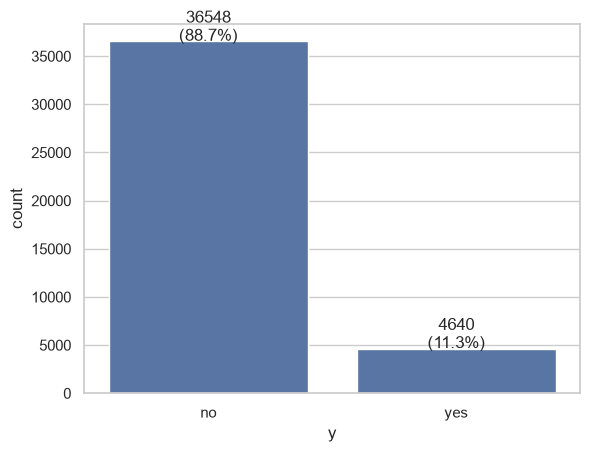

In [10]:
ax = sns.countplot(data=df, x="y")
total = len(df)
for p in ax.patches:
    count = int(p.get_height()) 
    percentage = f'{100 * count / total:.1f}%'
    ax.annotate(f'{count}\n({percentage})', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 10), 
                textcoords='offset points')
plt.show()

Имеет место выраженный дисбаланс классов: целевая переменная y распределена крайне неравномерно. Клиентов, отказавшихся от предложения, 88.7% (36 548 человек). Клиентов, согласившихся на вклад, 11.3% (4 640 человек). Соотношение — примерно 8 к 1.

# Подготовка к анализу данных.

In [11]:
base_rate = (df["y"] == "yes").mean()
print(f"Базовая доля ответов yes: {base_rate:.3f}")
df["y_num"] = (df["y"] == "yes").astype(int)
months = ["mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
df["month"] = pd.Categorical(df["month"], categories=months, ordered=True)

Базовая доля ответов yes: 0.113


# Анализ истории контактов.

## Обнаружение неявного пропуска в данных о количестве дней, прошедших с момента последнего контакта банка с клиентом.

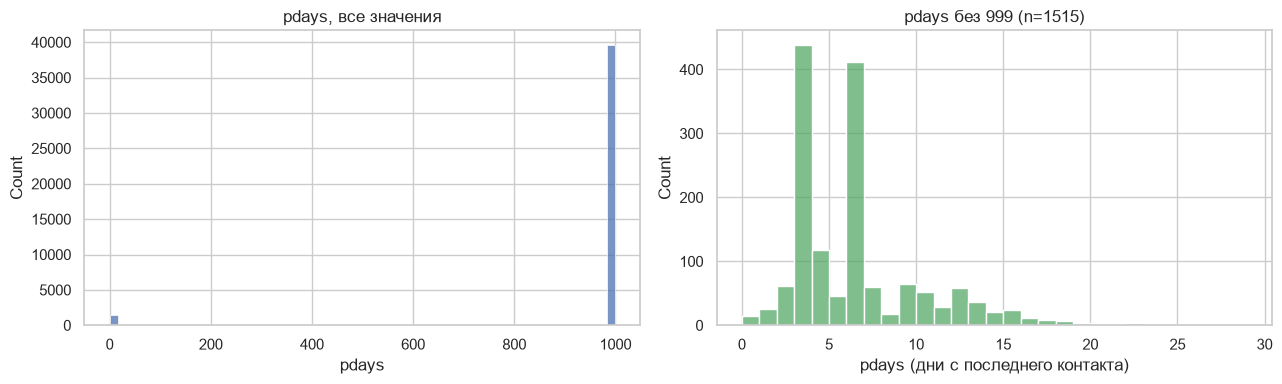

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# слева: всё как есть — 999 доминирует, реальные дни не видны
sns.histplot(df["pdays"], bins=60, ax=axes[0], color="C0")
axes[0].set_title("pdays, все значения")
axes[0].set_xlabel("pdays")

# справа: только те, где pdays != 999 — вот это и есть "настоящие" дни
real = df.loc[df["pdays"] != 999, "pdays"]
sns.histplot(real, bins=range(0, 30), ax=axes[1], color="C2")
axes[1].set_title(f"pdays без 999 (n={len(real)})")
axes[1].set_xlabel("pdays (дни с последнего контакта)")

plt.tight_layout(); plt.show()

Из приведённых выше графиков видно, что значение 999 явно не соответствует количеству дней, прошедших с момента последнего контакта банка с клиентом, а соответсвует отсутствию такового вообще.

## Обнаружение неявных пропусков в данных со значением unknown.

In [13]:
unk_counts = (df == "unknown").sum()
unk_counts = unk_counts[unk_counts > 0].sort_values(ascending=False)

implicit_na = pd.DataFrame({
    "column":        unk_counts.index,
    "count_unknown": unk_counts.values,
    "dtype":         [df[c].dtype for c in unk_counts.index],
}).reset_index(drop=True)

implicit_na

,column,count_unknown,dtype
0,default,8597,string
1,education,1731,string
2,housing,990,string
3,loan,990,string
4,job,330,string
5,marital,80,string


В ходе анализа было выявлено 6 категориальных признаков, содержащих неявные пропуски, закодированные строкой unknown.
Наибольшая доля пропусков наблюдается в признаке default (8597 записей).

## Обработка данных о количестве дней, прошедших с момента последнего контакта банка с клиентом.

In [14]:
df["was_contacted_before"] = df["pdays"] != 999

Для корректного использования этого признака в анализе была проведена следующая обработка: создан бинарный признак was_contacted_before, принимающий значение True, если клиента беспокоили ранее, и значение False, если нет (это позволит сохранить информацию о факте прошлого взаимодействия);

# Визуализации анализируемых данных.

In [21]:
df["is_yes"] = (df["y"] == "yes").astype(int)

## Анализ истории контактов.

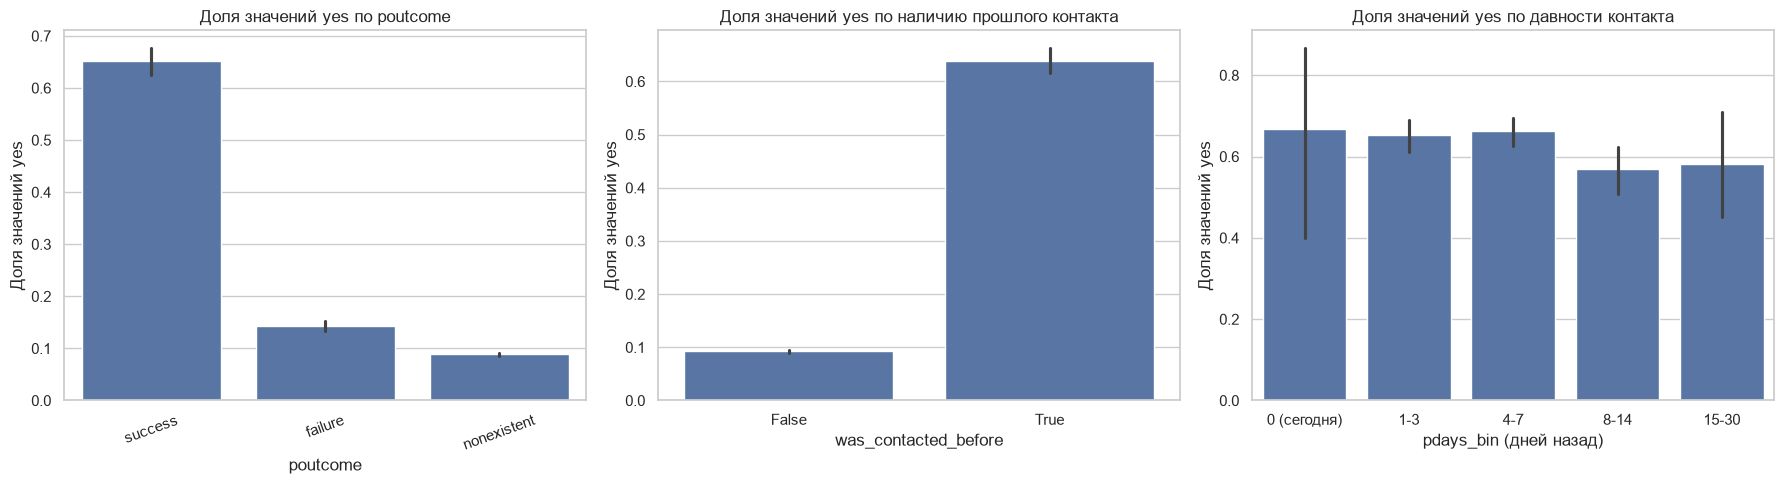

In [22]:
labels = ['0 (сегодня)', '1-3', '4-7', '8-14', '15-30']
df['pdays_bin'] = pd.cut(df['pdays'], bins=[-1, 0, 3, 7, 14, 30], labels=labels)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(
    data=df, x="poutcome", y="is_yes",
    order=df.groupby("poutcome")["is_yes"].mean().sort_values(ascending=False).index,
    ax=axes[0]
)
axes[0].set_title("Доля значений yes по poutcome")
axes[0].set_ylabel("Доля значений yes")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=df, x="was_contacted_before", y="is_yes", ax=axes[1])
axes[1].set_title("Доля значений yes по наличию прошлого контакта")
axes[1].set_xlabel("was_contacted_before")
axes[1].set_ylabel("Доля значений yes")

sns.barplot(data=df, x="pdays_bin", y="is_yes", ax=axes[2])
axes[2].set_title("Доля значений yes по давности контакта")
axes[2].set_xlabel("pdays_bin (дней назад)")
axes[2].set_ylabel("Доля значений yes")

plt.tight_layout()
plt.show()

Анализ трех графиков показывает колоссальное влияние истории прошлых взаимодействий на результат кампании.
1. Результат прошлой кампании (poutcome). Это один из самых сильных предикторов. Если клиент в прошлом уже согласился на предложение банка (success), вероятность его согласия сейчас составляет около 65%. 
2. Факт прошлого контакта (was_contacted_before). Для клиентов, с которыми ранее не связывались (0), доля согласий минимальна (~8%). Если контакт в прошлом был (1), вероятность согласия возрастает более чем в 6 раз, превышая 60%.
3. Давность контакта (pdays_bin). Если клиента уже беспокоили ранее, давность последнего контакта играет меньшую роль.

Результаты анализа данных банка указывают на то, что клиенты с позитивным опытом или с недавним контактом приносят основную массу согласий. 

# Анализ отклика клиентов на срочный вклад

В этом разделе мы сравниваем, какие группы клиентов чаще соглашались открыть вклад, как отличались результаты по месяцам и способам связи и как с откликом были связаны экономические показатели. 

Для расчётов использованы все 41 188 строк исходной таблицы. В данных есть 12 полностью совпадающих строк. Мы оставили их в расчетах: в наборе нет номера клиента, поэтому по этим данным нельзя понять, являются ли совпадения повторными звонками одному человеку.

## 1. Какие группы клиентов чаще соглашались открыть вклад?

Чтобы сравнить группы, посчитали число контактов и число оформленных вкладов в каждой группе, затем рассчитали долю отклика по формуле:

**число ответов `yes` / число всех контактов в группе × 100%.**

Также посчитали, какую часть всех оформленных вкладов дала каждая группа. Например, процент отклика показывает, насколько часто соглашались клиенты внутри группы, а число оформлений показывает, сколько вкладов в итоге получилось.

In [23]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 65, 120],
    labels=["до 25", "26–35", "36–45", "46–55", "56–65", "66+"],
)

category_names = {
    "job": {
        "admin.": "административный персонал", "blue-collar": "рабочие специальности",
        "entrepreneur": "предприниматели", "housemaid": "домашний персонал",
        "management": "управленцы", "retired": "пенсионеры",
        "self-employed": "самозанятые", "services": "сфера услуг",
        "student": "студенты", "technician": "технические специалисты",
        "unemployed": "безработные", "unknown": "неизвестно",
    },
    "marital": {"married": "в браке", "single": "не в браке", "divorced": "в разводе", "unknown": "неизвестно"},
    "education": {
        "basic.4y": "базовое образование, 4 года", "basic.6y": "базовое образование, 6 лет",
        "basic.9y": "базовое образование, 9 лет", "high.school": "среднее образование",
        "illiterate": "без образования", "professional.course": "профессиональное образование",
        "university.degree": "высшее образование", "unknown": "неизвестно",
    },
    "default": {"yes": "да", "no": "нет", "unknown": "неизвестно"},
    "housing": {"yes": "да", "no": "нет", "unknown": "неизвестно"},
    "loan": {"yes": "да", "no": "нет", "unknown": "неизвестно"},
}

def response_by_segment(data, column):
    result = (
        data.groupby(column, dropna=False, observed=True)["is_yes"]
        .agg(contacts="size", deposits="sum", response_rate="mean")
        .sort_values("response_rate", ascending=False)
    )
    result["response_rate_pct"] = (100 * result["response_rate"]).round(1)
    result["share_of_all_yes_pct"] = (100 * result["deposits"] / data["is_yes"].sum()).round(1)
    return result

profile_columns = ["age_group", "job", "marital", "education", "default", "housing", "loan"]
profile_labels = {
    "age_group": "Возраст", "job": "Профессия", "marital": "Семейное положение",
    "education": "Образование", "default": "Кредитная задолженность",
    "housing": "Жилищный кредит", "loan": "Личный кредит",
}
profile_tables = {}
for column in profile_columns:
    profile_tables[column] = response_by_segment(df, column)
    print(f"\nОтклик по полю «{profile_labels[column]}»")
    table = profile_tables[column][["contacts", "deposits", "response_rate_pct", "share_of_all_yes_pct"]].copy()
    table.index = [category_names.get(column, {}).get(str(value), str(value)) for value in table.index]
    table = table.rename(columns={
        "contacts": "Контакты", "deposits": "Оформили вклад",
        "response_rate_pct": "Отклик в группе, %",
        "share_of_all_yes_pct": "Доля от всех вкладов, %",
    })
    display(table)


Отклик по полю «Возраст»


,Контакты,Оформили вклад,"Отклик в группе, %","Доля от всех вкладов, %"
66+,619,290,46.8,6.2
до 25,1666,349,20.9,7.5
56–65,2963,451,15.2,9.7
26–35,14847,1740,11.7,37.5
46–55,8249,717,8.7,15.5
36–45,12844,1093,8.5,23.6



Отклик по полю «Профессия»


,Контакты,Оформили вклад,"Отклик в группе, %","Доля от всех вкладов, %"
студенты,875,275,31.4,5.9
пенсионеры,1720,434,25.2,9.4
безработные,1014,144,14.2,3.1
административный персонал,10422,1352,13.0,29.1
управленцы,2924,328,11.2,7.1
неизвестно,330,37,11.2,0.8
технические специалисты,6743,730,10.8,15.7
самозанятые,1421,149,10.5,3.2
домашний персонал,1060,106,10.0,2.3
предприниматели,1456,124,8.5,2.7



Отклик по полю «Семейное положение»


,Контакты,Оформили вклад,"Отклик в группе, %","Доля от всех вкладов, %"
неизвестно,80,12,15.0,0.3
не в браке,11568,1620,14.0,34.9
в разводе,4612,476,10.3,10.3
в браке,24928,2532,10.2,54.6


... (4 outputs left out)


Отклик по полю «Жилищный кредит»


,Контакты,Оформили вклад,"Отклик в группе, %","Доля от всех вкладов, %"
да,21576,2507,11.6,54.0
нет,18622,2026,10.9,43.7
неизвестно,990,107,10.8,2.3



Отклик по полю «Личный кредит»


,Контакты,Оформили вклад,"Отклик в группе, %","Доля от всех вкладов, %"
нет,33950,3850,11.3,83.0
да,6248,683,10.9,14.7
неизвестно,990,107,10.8,2.3


На графиках показана доля отклика внутри каждой группы. Размер группы можно посмотреть в таблице выше: это важно, потому что одинаковые проценты могут быть получены на разном количестве контактов.

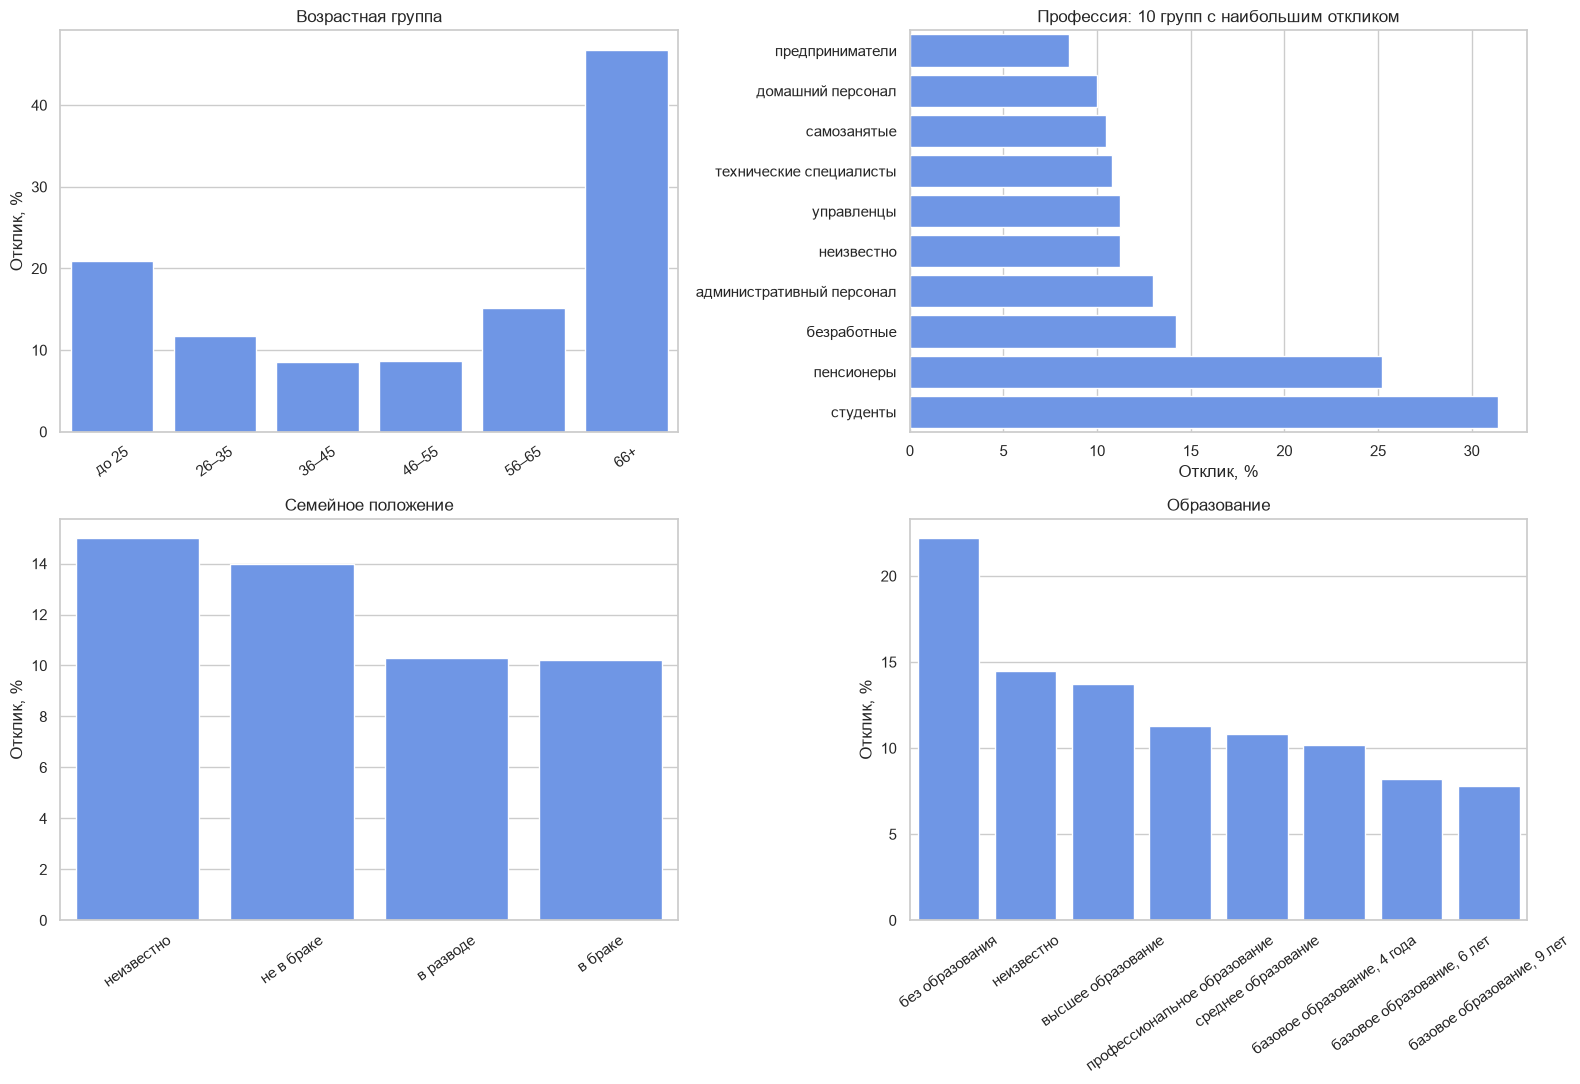

In [24]:
plot_columns = ["age_group", "job", "marital", "education"]
plot_titles = {
    "age_group": "Возрастная группа", "job": "Профессия: 10 групп с наибольшим откликом",
    "marital": "Семейное положение", "education": "Образование",
}
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, column in zip(axes.flat, plot_columns):
    table = profile_tables[column].sort_values("response_rate_pct", ascending=False).reset_index()
    if column in category_names:
        table[column] = table[column].map(lambda value: category_names[column].get(str(value), str(value)))
    if column == "job":
        table = table.head(10).sort_values("response_rate_pct")
        sns.barplot(data=table, y=column, x="response_rate_pct", color="#5B8FF9", ax=ax)
        ax.set_xlabel("Отклик, %")
        ax.set_ylabel("")
    else:
        sns.barplot(data=table, x=column, y="response_rate_pct", color="#5B8FF9", ax=ax)
        ax.set_xlabel("")
        ax.set_ylabel("Отклик, %")
        ax.tick_params(axis="x", rotation=35)
    ax.set_title(plot_titles[column])
plt.tight_layout()
plt.show()


### Что получилось при сравнении групп

Самая высокая доля отклика по возрасту получилась у клиентов 66 лет и старше — 46,8%. Это 290 вкладов из 619 контактов. При этом на эту возрастную группу приходится около 6% всех оформленных вкладов.

По профессии чаще соглашались студенты — 31,4% (275 из 875), затем пенсионеры — 25,2% (434 из 1 720). Больше всего вкладов оформили клиенты 26–35 лет: 1 740, или 37,5% от всех вкладов. Доля отклика в этой группе — 11,7%.

Получается, что одной доли недостаточно: полезно смотреть и на процент, и на количество контактов. Например, в группе «без образования» всего 18 контактов, поэтому её результат может сильно измениться от нескольких ответов. Эти данные показывают связь, но не доказывают, что возраст или профессия стали причиной решения.

## 2. Результаты по месяцам и способам связи

Для каждого месяца и способа связи мы посчитали число контактов, число оформленных вкладов и долю отклика. Ещё посмотрели, сколько вкладов в целом пришлось на каждый месяц и способ связи. Так можно сравнить и процент, и количество результатов.

In [25]:
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_names = {"mar": "Март", "apr": "Апрель", "may": "Май", "jun": "Июнь", "jul": "Июль", "aug": "Август", "sep": "Сентябрь", "oct": "Октябрь", "nov": "Ноябрь", "dec": "Декабрь"}
month_short = {"mar": "мар", "apr": "апр", "may": "май", "jun": "июн", "jul": "июл", "aug": "авг", "sep": "сен", "oct": "окт", "nov": "ноя", "dec": "дек"}
contact_names = {"cellular": "мобильная связь", "telephone": "телефон"}
df["month"] = pd.Categorical(df["month"], categories=month_order, ordered=True)

monthly = (
    df.groupby("month", observed=False)["is_yes"]
    .agg(contacts="size", deposits="sum", response_rate="mean")
)
monthly["response_rate_pct"] = (100 * monthly["response_rate"]).round(1)
monthly["share_of_all_deposits_pct"] = (100 * monthly["deposits"] / df["is_yes"].sum()).round(1)
monthly_view = monthly.copy()
monthly_view.index = [month_names[str(month)] for month in monthly.index]
monthly_view = monthly_view.rename(columns={
    "contacts": "Контакты", "deposits": "Оформили вклад",
    "response_rate": "Доля отклика", "response_rate_pct": "Отклик, %",
    "share_of_all_deposits_pct": "Доля от всех вкладов, %",
})
print("Результаты по месяцам")
display(monthly_view)

channel = (
    df.groupby("contact")["is_yes"]
    .agg(contacts="size", deposits="sum", response_rate="mean")
)
channel["response_rate_pct"] = (100 * channel["response_rate"]).round(1)
channel["share_of_all_deposits_pct"] = (100 * channel["deposits"] / df["is_yes"].sum()).round(1)
channel_view = channel.copy()
channel_view.index = [contact_names.get(str(value), str(value)) for value in channel.index]
channel_view = channel_view.rename(columns={
    "contacts": "Контакты", "deposits": "Оформили вклад",
    "response_rate": "Доля отклика", "response_rate_pct": "Отклик, %",
    "share_of_all_deposits_pct": "Доля от всех вкладов, %",
})
print("Результаты по каналам связи")
display(channel_view)

Результаты по месяцам


,Контакты,Оформили вклад,Доля отклика,"Отклик, %","Доля от всех вкладов, %"
Март,546,276,0.505495,50.5,5.9
Апрель,2632,539,0.204787,20.5,11.6
Май,13769,886,0.064347,6.4,19.1
Июнь,5318,559,0.105115,10.5,12.0
Июль,7174,649,0.090466,9.0,14.0
Август,6178,655,0.106021,10.6,14.1
Сентябрь,570,256,0.449123,44.9,5.5
Октябрь,718,315,0.438719,43.9,6.8
Ноябрь,4101,416,0.101439,10.1,9.0
Декабрь,182,89,0.489011,48.9,1.9


Результаты по каналам связи


,Контакты,Оформили вклад,Доля отклика,"Отклик, %","Доля от всех вкладов, %"
мобильная связь,26144,3853,0.147376,14.7,83.0
телефон,15044,787,0.052313,5.2,17.0


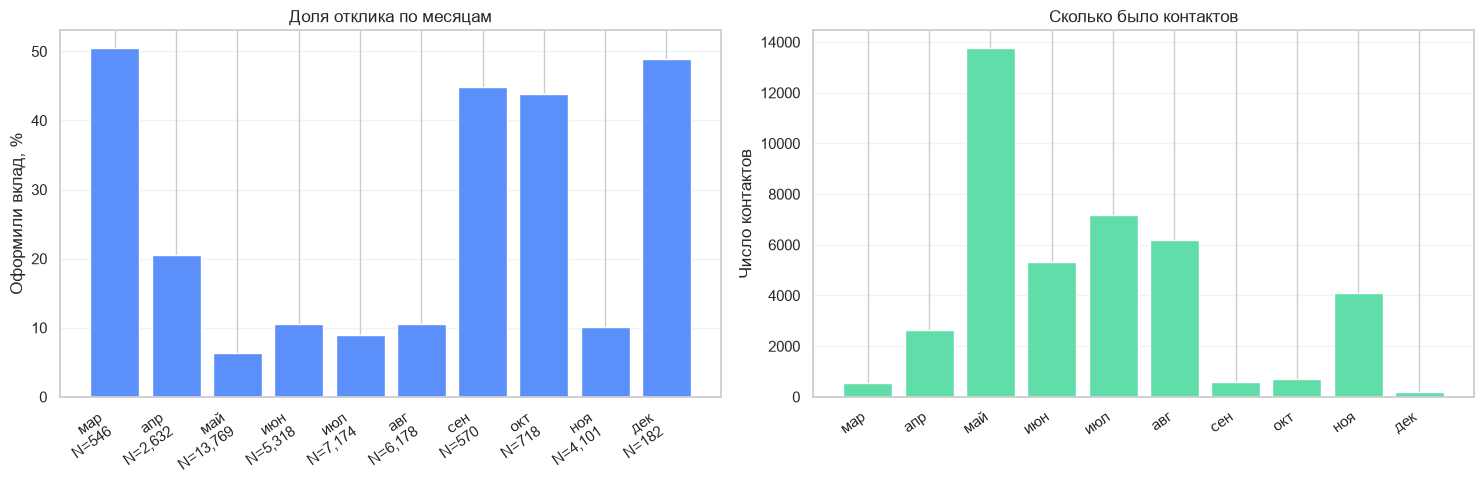

Результат отдельно для каждого месяца и канала


,Месяц,Канал связи,Контакты,Оформили вклад,"Отклик, %"
0,Март,мобильная связь,486,252,51.9
1,Март,телефон,60,24,40.0
2,Апрель,мобильная связь,2445,493,20.2
3,Апрель,телефон,187,46,24.6
4,Май,мобильная связь,5518,614,11.1
5,Май,телефон,8251,272,3.3
6,Июнь,мобильная связь,820,349,42.6
7,Июнь,телефон,4498,210,4.7
8,Июль,мобильная связь,6096,591,9.7
9,Июль,телефон,1078,58,5.4


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
month_labels = [f"{month_short[str(month)]}\nN={count:,}" for month, count in zip(monthly.index, monthly["contacts"])]
axes[0].bar(range(len(monthly)), monthly["response_rate_pct"], color="#5B8FF9")
axes[0].set_title("Доля отклика по месяцам")
axes[0].set_ylabel("Оформили вклад, %")
axes[0].set_xticks(range(len(monthly)), month_labels, rotation=35, ha="right")
axes[0].grid(axis="y", alpha=0.25)
axes[1].bar(range(len(monthly)), monthly["contacts"], color="#61DDAA")
axes[1].set_title("Сколько было контактов")
axes[1].set_ylabel("Число контактов")
axes[1].set_xticks(range(len(monthly)), [month_short[str(month)] for month in monthly.index], rotation=35, ha="right")
axes[1].grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

month_channel = (
    df.groupby(["month", "contact"], observed=True)["is_yes"]
    .agg(contacts="size", deposits="sum", response_rate="mean")
    .reset_index()
)
month_channel["response_rate_pct"] = (100 * month_channel["response_rate"]).round(1)
month_channel_view = month_channel[["month", "contact", "contacts", "deposits", "response_rate_pct"]].copy()
month_channel_view["month"] = month_channel_view["month"].astype(str).map(month_names)
month_channel_view["contact"] = month_channel_view["contact"].map(contact_names)
month_channel_view = month_channel_view.rename(columns={
    "month": "Месяц", "contact": "Канал связи", "contacts": "Контакты",
    "deposits": "Оформили вклад", "response_rate_pct": "Отклик, %",
})
print("Результат отдельно для каждого месяца и канала")
display(month_channel_view)

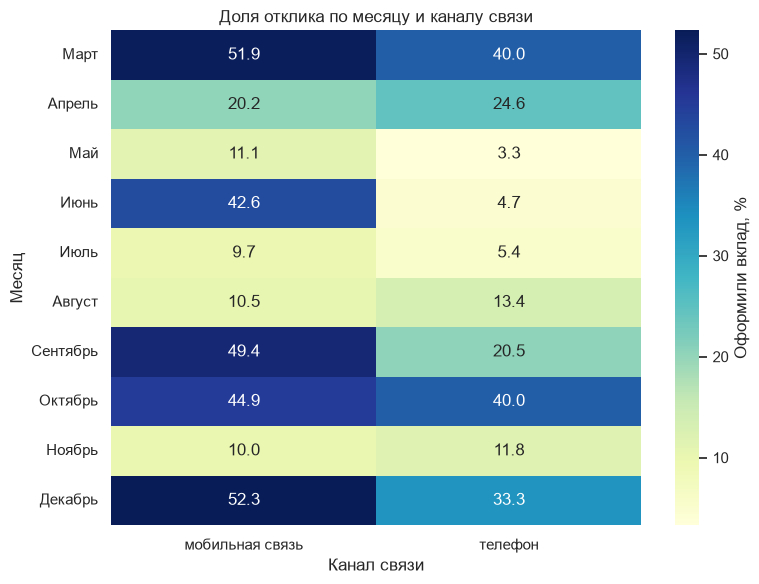

In [27]:
rate_matrix = month_channel.pivot(index="month", columns="contact", values="response_rate_pct").reindex(month_order)
rate_matrix.index = [month_names[str(month)] for month in rate_matrix.index]
rate_matrix = rate_matrix.rename(columns=contact_names)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(rate_matrix, annot=True, fmt=".1f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "Оформили вклад, %"})
ax.set_title("Доля отклика по месяцу и каналу связи")
ax.set_xlabel("Канал связи")
ax.set_ylabel("Месяц")
plt.tight_layout()
plt.show()

### Что получилось по месяцам и способам связи

По мобильной связи доля отклика составила 14,7% (3 853 вклада из 26 144 контактов). По телефону — 5,2% (787 из 15 044). Если посмотреть отдельно по месяцам, разница между способами связи меняется.

Самая высокая доля отклика была в марте — 50,5% (276 вкладов из 546 контактов). В мае доля составила 6,4%, но контактов было больше всего — 13 769; вклад оформили 886 человек.

В таблице есть данные за несколько лет, а полной даты для каждой записи нет. Поэтому по этим результатам нельзя уверенно сказать, что дело именно в месяце: на них могли повлиять и другие изменения в кампании или экономике.

## 3. Экономические показатели

В спавнении мы использовали пять экономических показателей у клиентов, которые оформили вклад (`yes`), и у тех, кто не оформил (`no`). Для сравнения использовала медиану — это середина ряда значений: примерно половина наблюдений ниже неё, половина выше.

Также посчитали корреляцию между показателями. Она показывает, меняются ли показатели похожим образом. Сама по себе корреляция не доказывает, что один показатель влияет на другой.

In [28]:
macro_columns = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
macro_names = {
    "emp.var.rate": "Изменение занятости",
    "cons.price.idx": "Индекс потребительских цен",
    "cons.conf.idx": "Индекс уверенности потребителей",
    "euribor3m": "Ставка Euribor на 3 месяца",
    "nr.employed": "Число занятых",
}
macro_medians = df.groupby("y")[macro_columns].median().T
macro_medians["difference_yes_minus_no"] = macro_medians["yes"] - macro_medians["no"]
macro_medians = macro_medians.rename(columns={
    "no": "Медиана: вклад не оформили",
    "yes": "Медиана: вклад оформили",
    "difference_yes_minus_no": "Разница: yes минус no",
})
macro_medians.index = [macro_names[value] for value in macro_medians.index]
print("Медианы экономических показателей в двух группах")
display(macro_medians.round(3))

macro_corr = df[macro_columns].corr()
macro_corr_view = macro_corr.rename(index=macro_names, columns=macro_names)
print("Насколько экономические показатели менялись вместе")
display(macro_corr_view.round(2))

Медианы экономических показателей в двух группах


y,Медиана: вклад не оформили,Медиана: вклад оформили,Разница: yes минус no
Изменение занятости,1.1,-1.8,-2.9
Индекс потребительских цен,93.918,93.2,-0.718
Индекс уверенности потребителей,-41.8,-40.4,1.4
Ставка Euribor на 3 месяца,4.857,1.266,-3.591
Число занятых,5195.8,5099.1,-96.7


Насколько экономические показатели менялись вместе


,Изменение занятости,Индекс потребительских цен,Индекс уверенности потребителей,Ставка Euribor на 3 месяца,Число занятых
Изменение занятости,1.00,0.78,0.20,0.97,0.91
Индекс потребительских цен,0.78,1.00,0.06,0.69,0.52
Индекс уверенности потребителей,0.20,0.06,1.00,0.28,0.10
Ставка Euribor на 3 месяца,0.97,0.69,0.28,1.00,0.95
Число занятых,0.91,0.52,0.10,0.95,1.00


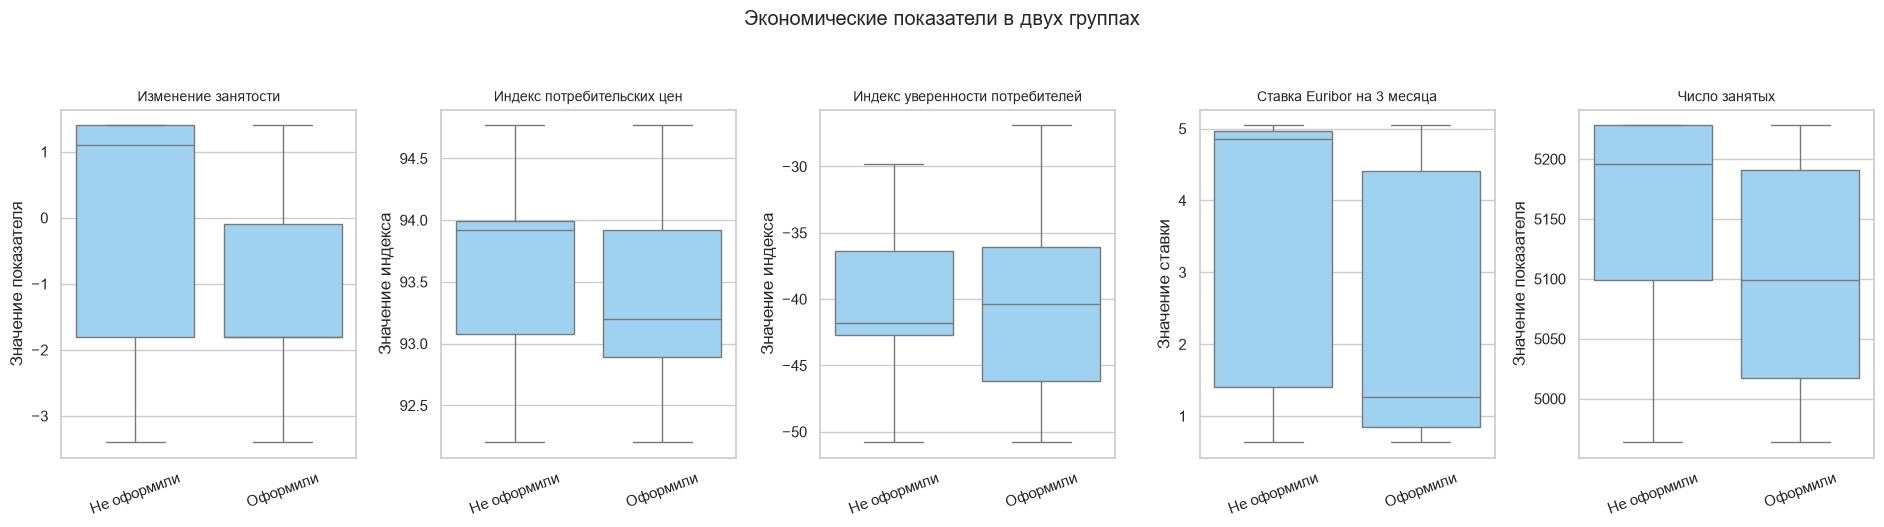

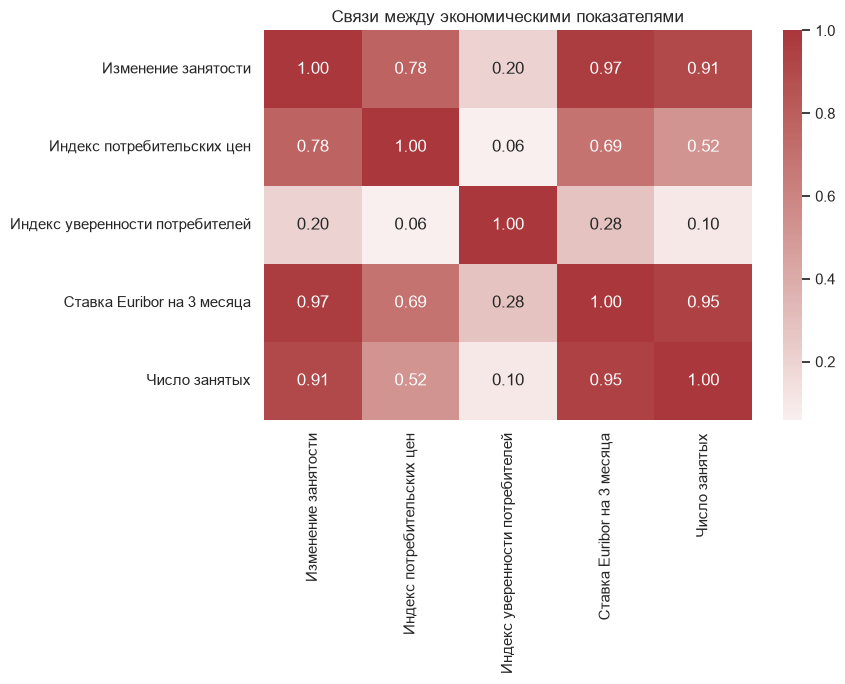

In [29]:
macro_units = {
    "emp.var.rate": "Значение показателя", "cons.price.idx": "Значение индекса",
    "cons.conf.idx": "Значение индекса", "euribor3m": "Значение ставки",
    "nr.employed": "Значение показателя",
}
fig, axes = plt.subplots(1, 5, figsize=(19, 5))
for ax, column in zip(axes, macro_columns):
    sns.boxplot(data=df, x="y", y=column, order=["no", "yes"], showfliers=False, ax=ax, color="#91D5FF")
    ax.set_title(macro_names[column], fontsize=10)
    ax.set_xlabel("")
    ax.set_xticks([0, 1], labels=["Не оформили", "Оформили"], rotation=20)
    ax.set_ylabel(macro_units[column])
plt.suptitle("Экономические показатели в двух группах", y=1.05)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(macro_corr_view, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Связи между экономическими показателями")
plt.tight_layout()
plt.show()

### Что видно по экономическим показателям

Медиана ставки Euribor в группе `yes` составила 1,266, а в группе `no` — 4,857. Медианное число занятых — 5 099,1 у тех, кто оформил вклад, и 5 195,8 у тех, кто не оформил. Для показателя изменения занятости медианы составили −1,8 и 1,1 соответственно.

В этих данных отклик чаще встречался при других значениях экономических показателей. Но это ещё не значит, что именно они повлияли на решение клиентов. Показатели относятся к периодам кампании и могут быть связаны с тем, когда проходили звонки.

Корреляция между изменением занятости и ставкой Euribor — около 0,97, а между ставкой Euribor и числом занятых — около 0,95. Значит, эти показатели в данных часто менялись вместе. При обучении модели стоит проверить, нужны ли они все одновременно.

## 4. Итог

Мы изучали, как отклик на предложение срочного вклада связан с характеристиками клиентов, месяцем контакта, способом связи и экономическими показателями. Вклад оформили 11,3% клиентов. Среди рассмотренных возрастных групп самая высокая доля отклика была у клиентов старше 66 лет — 46,8%. При этом больше всего вкладов оформили клиенты 26–35 лет — 1 740. Это показывает, почему важно учитывать и долю отклика, и количество оформленных вкладов.

В этой выборке доля отклика при мобильной связи составила 14,7%, а при телефонной — 5,2%. В марте доля отклика была самой высокой — 50,5%, а в мае было больше всего контактов и оформленных вкладов. Медианные значения экономических показателей также различались у клиентов с ответами yes и no; часть этих показателей сильно связана между собой.

Результаты помогли нам выделить признаки для проверки в модели. Следующий шаг — разделить имеющийся датасет на обучающую и проверочную части и оценить качество модели на этих данных. Если модель должна выбирать клиентов до звонка, duration использовать нельзя, потому что длительность разговора становится известна только после него.